#Part-Of-Speech


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df_all = pd.read_csv("pos_all.csv")
df_sin = pd.read_csv("pos_sin.csv")
df_esp = pd.read_csv("pos_esp.csv")

###Spontaneous (natural) dialogues

In [ ]:
df_esp

,POS,Freq_esp,Frecuencia relativa
0,PROPN,452,0.105435
1,NOUN,429,0.100070
2,VERB,414,0.096571
3,PRON,364,0.084908
4,ADP,259,0.060415
5,DET,252,0.058782
6,ADV,239,0.055750
7,AUX,127,0.029624
8,ADJ,114,0.026592
9,INTJ,95,0.022160


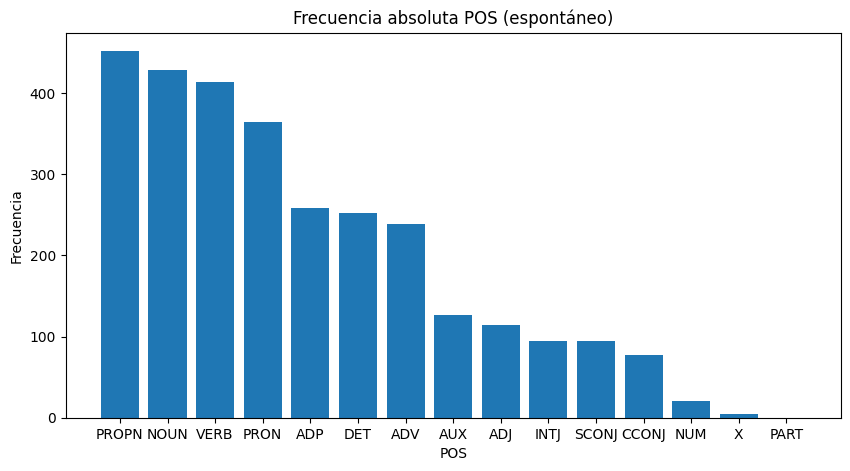

In [ ]:
plt.figure(figsize=(10,5))
plt.bar(df_esp["POS"], df_esp["Freq_esp"])
plt.title("Frecuencia absoluta POS (espontáneo)")
plt.xlabel("POS")
plt.ylabel("Frecuencia")
plt.show()

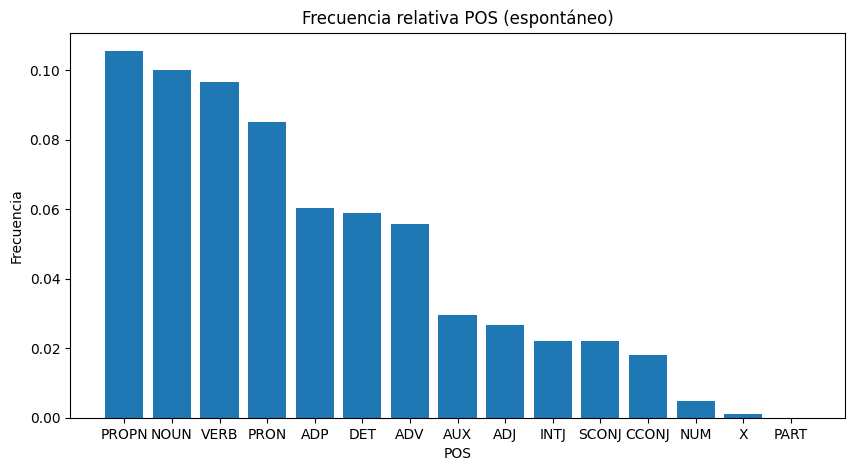

In [ ]:
plt.figure(figsize=(10,5))
plt.bar(df_esp["POS"], df_esp["Frecuencia relativa"])
plt.title("Frecuencia relativa POS (espontáneo)")
plt.xlabel("POS")
plt.ylabel("Frecuencia")
plt.show()

###Synthethic dialogues

In [ ]:
df_sin

,POS,Freq_sin,Frecuencia relativa
0,NOUN,771,0.144490
1,DET,543,0.101762
2,VERB,527,0.098763
3,ADP,492,0.092204
4,PRON,409,0.076649
5,ADV,304,0.056972
6,SCONJ,291,0.054535
7,ADJ,257,0.048163
8,PROPN,247,0.046289
9,CCONJ,162,0.030360


Text(0, 0.5, 'Frecuencia')

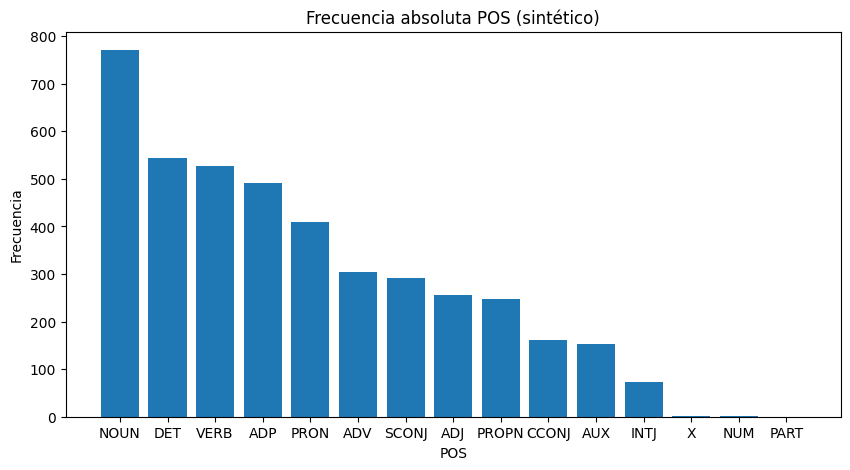

In [ ]:
plt.figure(figsize=(10,5))
plt.bar(df_sin["POS"], df_sin["Freq_sin"])
plt.title("Frecuencia absoluta POS (sintético)")
plt.xlabel("POS")
plt.ylabel("Frecuencia")

Text(0, 0.5, 'Frecuencia')

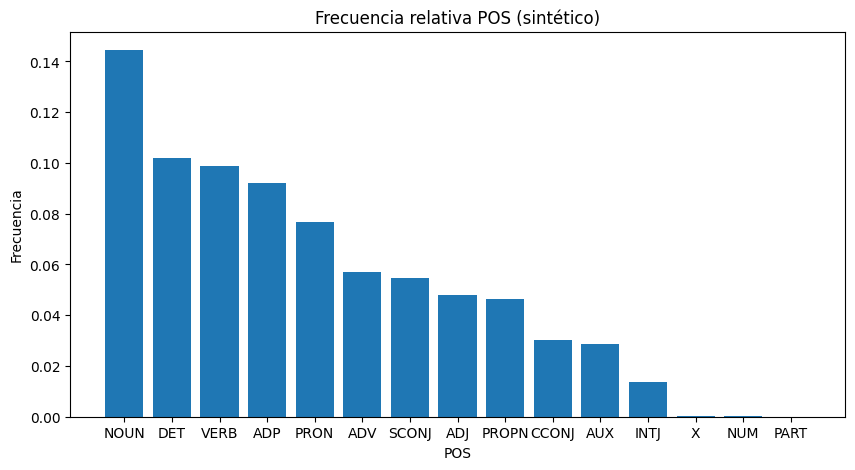

In [ ]:
plt.figure(figsize=(10,5))
plt.bar(df_sin["POS"], df_sin["Frecuencia relativa"])
plt.title("Frecuencia relativa POS (sintético)")
plt.xlabel("POS")
plt.ylabel("Frecuencia")

##All synthetic dialogues


In [ ]:
df_all

,POS,Freq_all,Frecuencia relativa
0,NOUN,5079,0.144520
1,VERB,3747,0.106618
2,DET,3642,0.103631
3,ADP,3497,0.099505
4,PRON,2744,0.078079
5,ADV,1963,0.055856
6,SCONJ,1741,0.049539
7,ADJ,1647,0.046864
8,PROPN,1416,0.040291
9,CCONJ,1032,0.029365


Text(0, 0.5, 'Frecuencia')

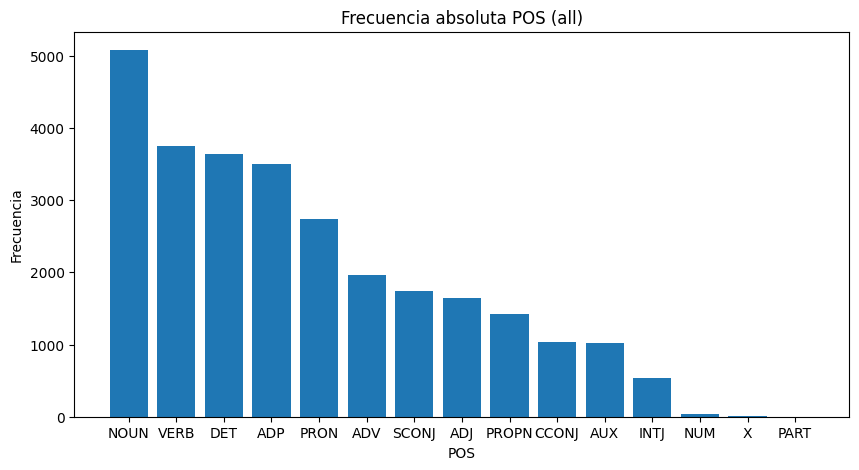

In [ ]:
plt.figure(figsize=(10,5))
plt.bar(df_all["POS"], df_all["Freq_all"])
plt.title("Frecuencia absoluta POS (all)")
plt.xlabel("POS")
plt.ylabel("Frecuencia")

Text(0, 0.5, 'Frecuencia')

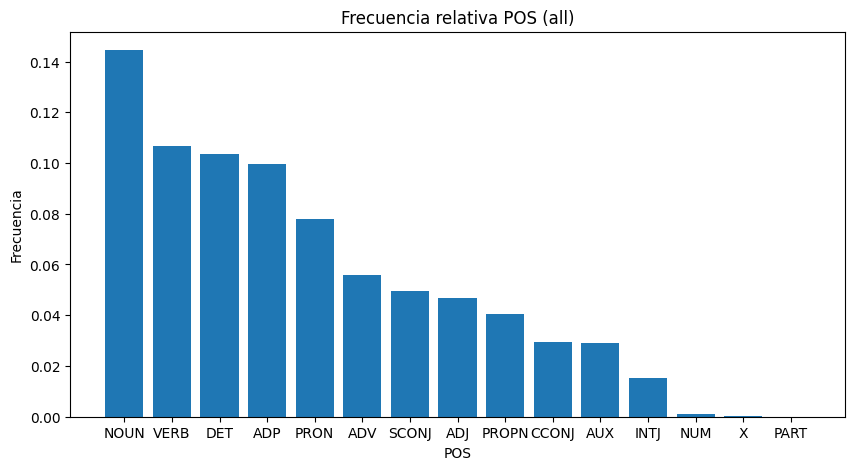

In [ ]:
plt.figure(figsize=(10,5))
plt.bar(df_all["POS"], df_all["Frecuencia relativa"])
plt.title("Frecuencia relativa POS (all)")
plt.xlabel("POS")
plt.ylabel("Frecuencia")

##Comparisons

###Diálogos espontáneos y diálogos sintéticos

In [ ]:
df_esp = df_esp.rename(columns={"Frecuencia": "Freq_esp"})
df_sin = df_sin.rename(columns={"Frecuencia": "Freq_sin"})

df_compare = pd.merge(
    df_esp,
    df_sin,
    on="POS",
    how="outer"
).fillna(0)

df_compare = df_compare.sort_values(by="Freq_esp",ascending=False)
df_compare = df_compare.sort_values(by="Freq_sin",ascending=False)

print(df_compare)

      POS  Freq_esp  Frecuencia relativa_x  Freq_sin  Frecuencia relativa_y
7    NOUN       429               0.100070       771               0.144490
5     DET       252               0.058782       543               0.101762
13   VERB       414               0.096571       527               0.098763
1     ADP       259               0.060415       492               0.092204
10   PRON       364               0.084908       409               0.076649
2     ADV       239               0.055750       304               0.056972
12  SCONJ        94               0.021927       291               0.054535
0     ADJ       114               0.026592       257               0.048163
11  PROPN       452               0.105435       247               0.046289
4   CCONJ        77               0.017961       162               0.030360
3     AUX       127               0.029624       152               0.028486
6    INTJ        95               0.022160        74               0.013868
8     NUM   

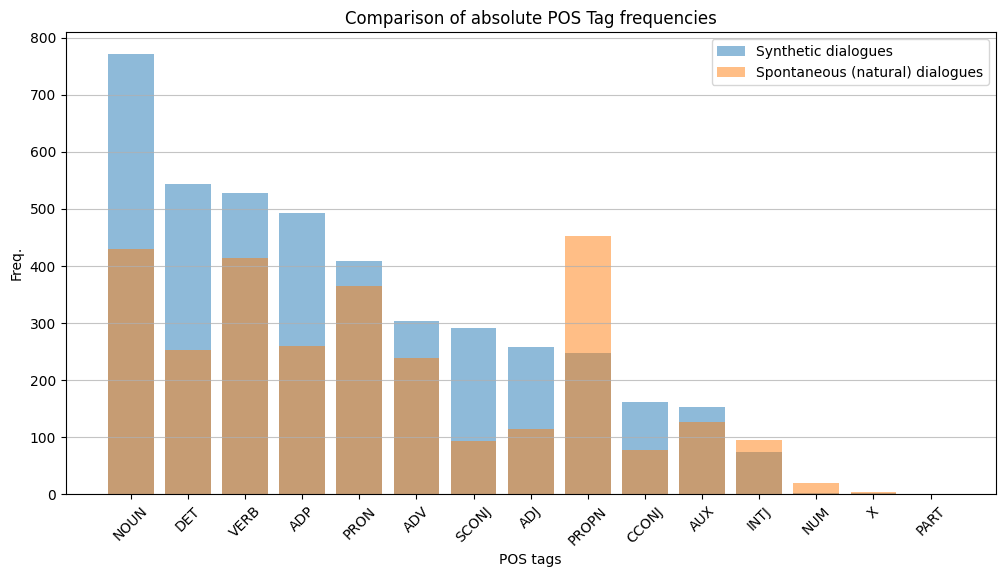

In [ ]:
import numpy as np

x = np.arange(len(df_compare["POS"]))

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_compare["Freq_sin"],
    alpha=0.5,
    label="Synthetic dialogues"
)

plt.bar(
    x,
    df_compare["Freq_esp"],
    alpha=0.5,
    label="Spontaneous (natural) dialogues"
)

plt.xlabel("POS tags")
plt.ylabel("Freq.")
plt.title('Comparison of absolute POS Tag frequencies')
plt.xticks(x, df_compare["POS"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

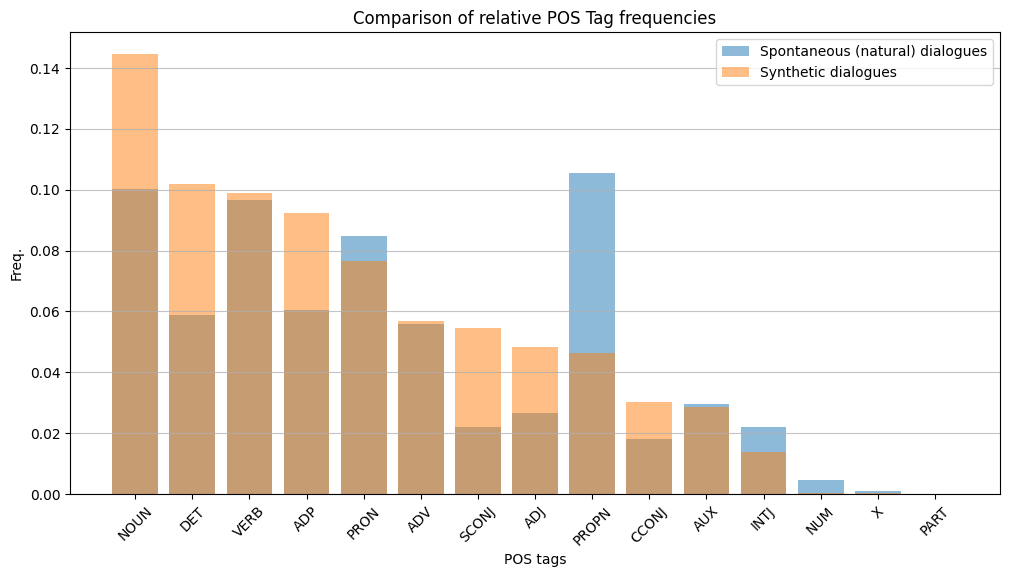

In [ ]:
import numpy as np

x = np.arange(len(df_compare["POS"]))

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_compare["Frecuencia relativa_x"],
    alpha=0.5,
    label="Spontaneous (natural) dialogues"
)

plt.bar(
    x,
    df_compare["Frecuencia relativa_y"],
    alpha=0.5,
    label="Synthetic dialogues"
)

plt.xlabel("POS tags")
plt.ylabel("Freq.")
plt.title('Comparison of relative POS Tag frequencies')
plt.xticks(x, df_compare["POS"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

###Diálogos espontáneos y diálogos sintéticos all

In [ ]:
df_esp = df_esp.rename(columns={"Frecuencia": "Freq_esp"})
df_all = df_all.rename(columns={"Frecuencia": "Freq_all"})

df_compare = pd.merge(
    df_esp,
    df_all,
    on="POS",
    how="outer"
).fillna(0)

df_compare = df_compare.sort_values(by="Freq_esp",ascending=False)
df_compare = df_compare.sort_values(by="Freq_all",ascending=False)

print(df_compare)

      POS  Freq_esp  Frecuencia relativa_x  Freq_all  Frecuencia relativa_y
7    NOUN       429               0.100070      5079               0.144520
13   VERB       414               0.096571      3747               0.106618
5     DET       252               0.058782      3642               0.103631
1     ADP       259               0.060415      3497               0.099505
10   PRON       364               0.084908      2744               0.078079
2     ADV       239               0.055750      1963               0.055856
12  SCONJ        94               0.021927      1741               0.049539
0     ADJ       114               0.026592      1647               0.046864
11  PROPN       452               0.105435      1416               0.040291
4   CCONJ        77               0.017961      1032               0.029365
3     AUX       127               0.029624      1026               0.029194
6    INTJ        95               0.022160       535               0.015223
8     NUM   

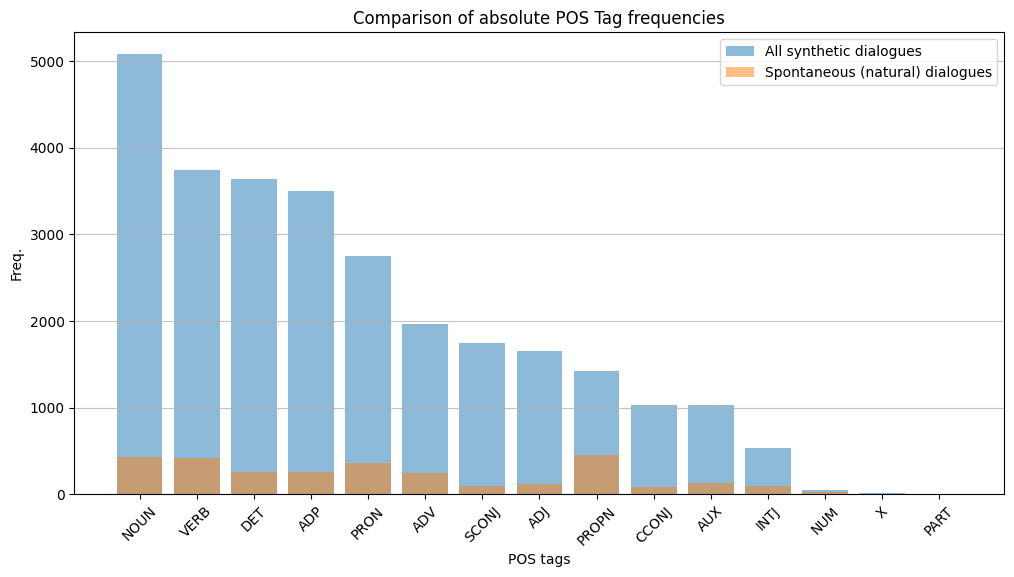

In [ ]:
x = np.arange(len(df_compare["POS"]))

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_compare["Freq_all"],
    alpha=0.5,
    label="All synthetic dialogues"
)

plt.bar(
    x,
    df_compare["Freq_esp"],
    alpha=0.5,
    label="Spontaneous (natural) dialogues"
)

plt.xlabel("POS tags")
plt.ylabel("Freq.")
plt.title( 'Comparison of absolute POS Tag frequencies')
plt.xticks(x, df_compare["POS"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

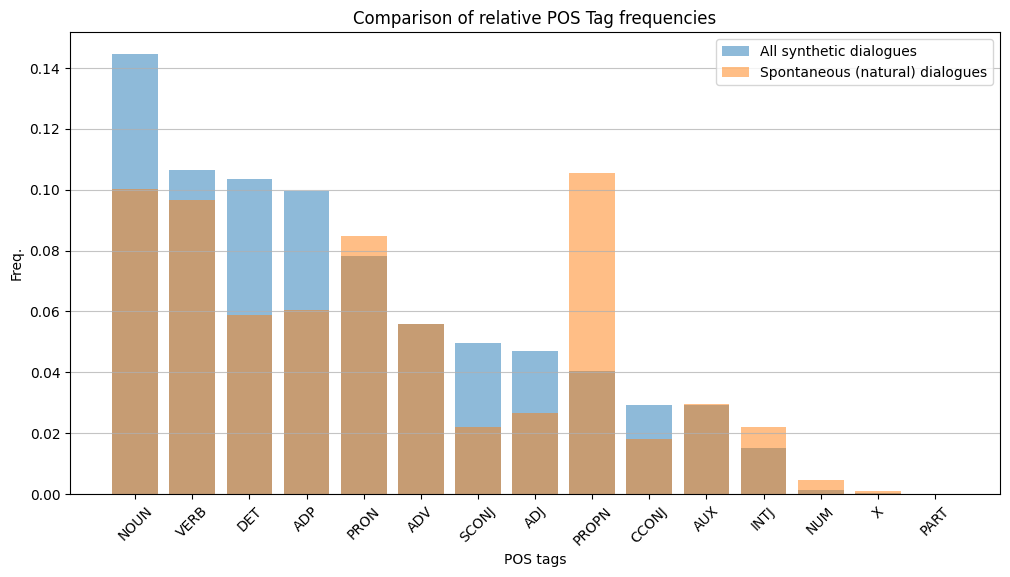

In [ ]:
x = np.arange(len(df_compare["POS"]))

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_compare["Frecuencia relativa_y"],
    alpha=0.5,
    label="All synthetic dialogues"
)

plt.bar(
    x,
    df_compare["Frecuencia relativa_x"],
    alpha=0.5,
    label="Spontaneous (natural) dialogues"
)

plt.xlabel("POS tags")
plt.ylabel("Freq.")
plt.title('Comparison of relative POS Tag frequencies')
plt.xticks(x, df_compare["POS"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

###Diálogos sintéticos y diálogos sintéticos all

In [ ]:
df_all = df_all.rename(columns={"Frecuencia": "Freq_all"})
df_sin = df_sin.rename(columns={"Frecuencia": "Freq_sin"})

df_compare = pd.merge(
    df_all,
    df_sin,
    on="POS",
    how="outer"
).fillna(0)

df_compare = df_compare.sort_values(by="Freq_all",ascending=False)
df_compare = df_compare.sort_values(by="Freq_sin",ascending=False)

print(df_compare)

      POS  Freq_all  Frecuencia relativa_x  Freq_sin  Frecuencia relativa_y
7    NOUN      5079               0.144520       771               0.144490
5     DET      3642               0.103631       543               0.101762
13   VERB      3747               0.106618       527               0.098763
1     ADP      3497               0.099505       492               0.092204
10   PRON      2744               0.078079       409               0.076649
2     ADV      1963               0.055856       304               0.056972
12  SCONJ      1741               0.049539       291               0.054535
0     ADJ      1647               0.046864       257               0.048163
11  PROPN      1416               0.040291       247               0.046289
4   CCONJ      1032               0.029365       162               0.030360
3     AUX      1026               0.029194       152               0.028486
6    INTJ       535               0.015223        74               0.013868
8     NUM   

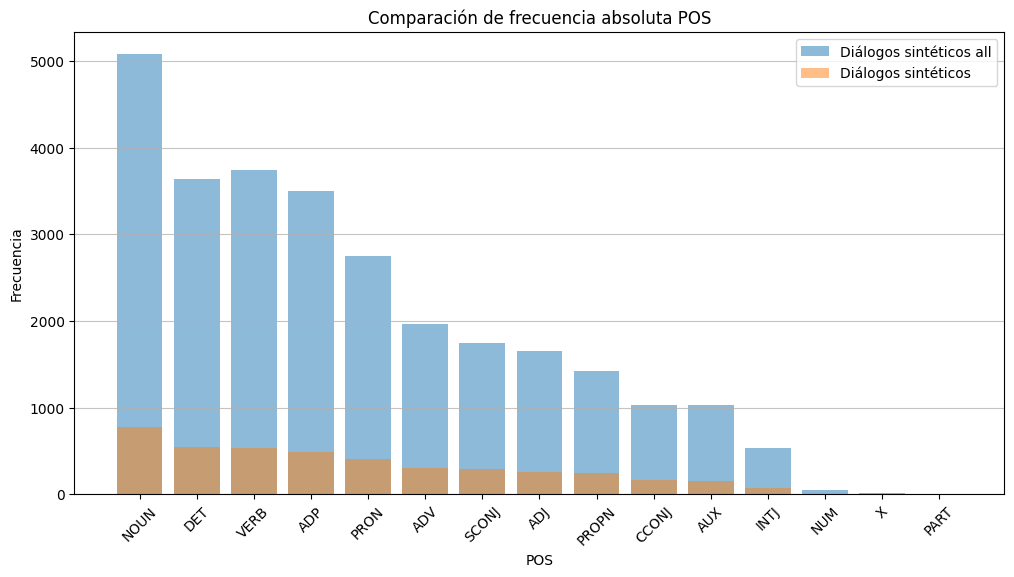

In [ ]:
x = np.arange(len(df_compare["POS"]))

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_compare["Freq_all"],
    alpha=0.5,
    label="Diálogos sintéticos all"
)

plt.bar(
    x,
    df_compare["Freq_sin"],
    alpha=0.5,
    label="Diálogos sintéticos"
)

plt.xlabel("POS")
plt.ylabel("Frecuencia")
plt.title("Comparación de frecuencia absoluta POS")
plt.xticks(x, df_compare["POS"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

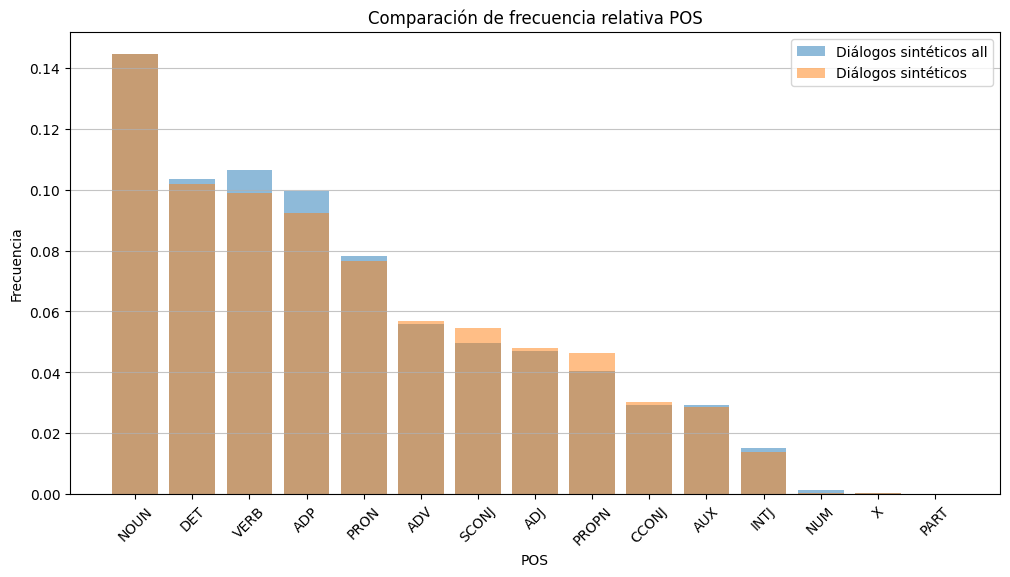

In [ ]:
x = np.arange(len(df_compare["POS"]))

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_compare["Frecuencia relativa_x"],
    alpha=0.5,
    label="Diálogos sintéticos all"
)

plt.bar(
    x,
    df_compare["Frecuencia relativa_y"],
    alpha=0.5,
    label="Diálogos sintéticos"
)

plt.xlabel("POS")
plt.ylabel("Frecuencia")
plt.title("Comparación de frecuencia relativa POS")
plt.xticks(x, df_compare["POS"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

##Syntactic dependencies

In [ ]:
df_ud_all = pd.read_csv("ud_all.csv")
df_ud_sin = pd.read_csv("ud_sin.csv")
df_ud_esp = pd.read_csv("ud_esp.csv")

###Diálogos espontáneos

In [ ]:
df_ud_esp

,Relación,Freq_ud_esp,Frec relativa
0,root,348,0.08118
1,advmod,268,0.06251
2,det,247,0.05762
3,appos,229,0.05342
4,obj,178,0.04152
5,case,172,0.04012
6,mark,166,0.03872
7,nsubj,158,0.03686
8,advcl,134,0.03126
9,conj,97,0.02263


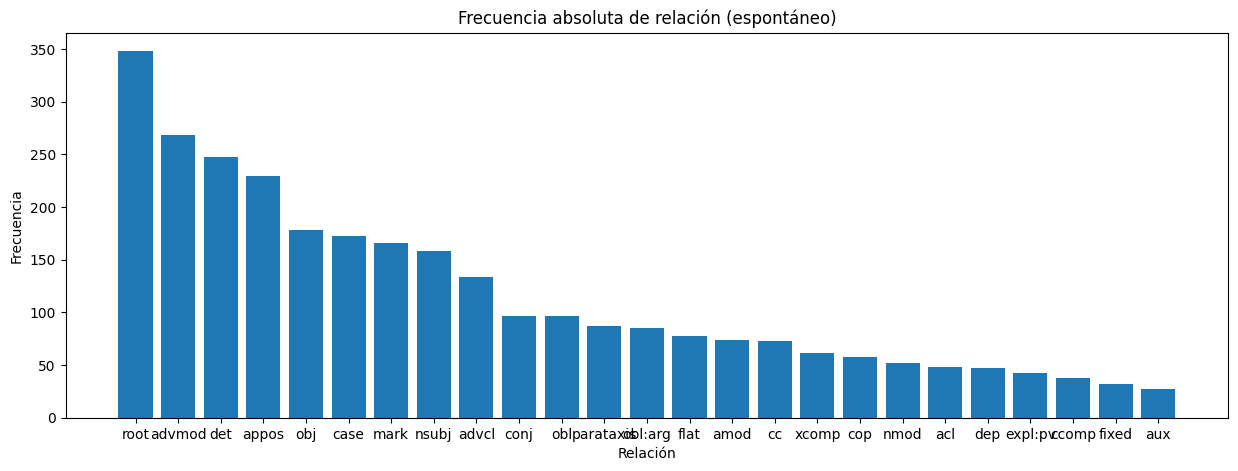

In [ ]:
plt.figure(figsize=(15,5))
plt.bar(df_ud_esp["Relación"], df_ud_esp["Freq_ud_esp"])
plt.title("Frecuencia absoluta de relación (espontáneo)")
plt.xlabel("Relación")
plt.ylabel("Frecuencia")
plt.show()

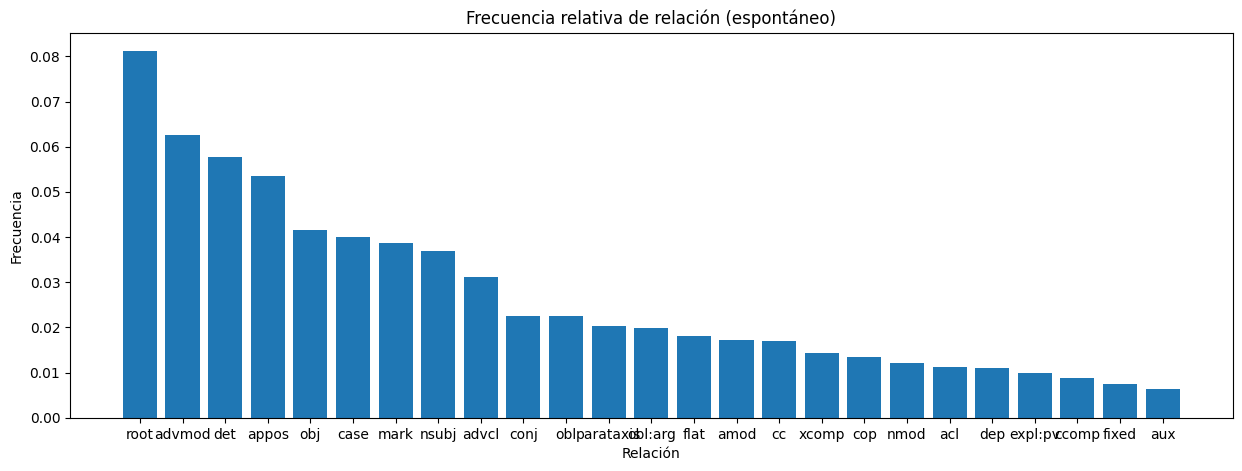

In [ ]:
plt.figure(figsize=(15,5))
plt.bar(df_ud_esp["Relación"], df_ud_esp["Frec relativa"])
plt.title("Frecuencia relativa de relación (espontáneo)")
plt.xlabel("Relación")
plt.ylabel("Frecuencia")
plt.show()

###Diálogos sintéticos

In [ ]:
df_ud_sin

,Relación,Freq_ud_sin,Frec relativa
0,det,541,0.10139
1,case,420,0.07871
2,mark,379,0.07103
3,advmod,322,0.06034
4,root,315,0.05903
5,nsubj,231,0.04329
6,obl,207,0.03879
7,amod,194,0.03636
8,obj,188,0.03523
9,nmod,185,0.03467


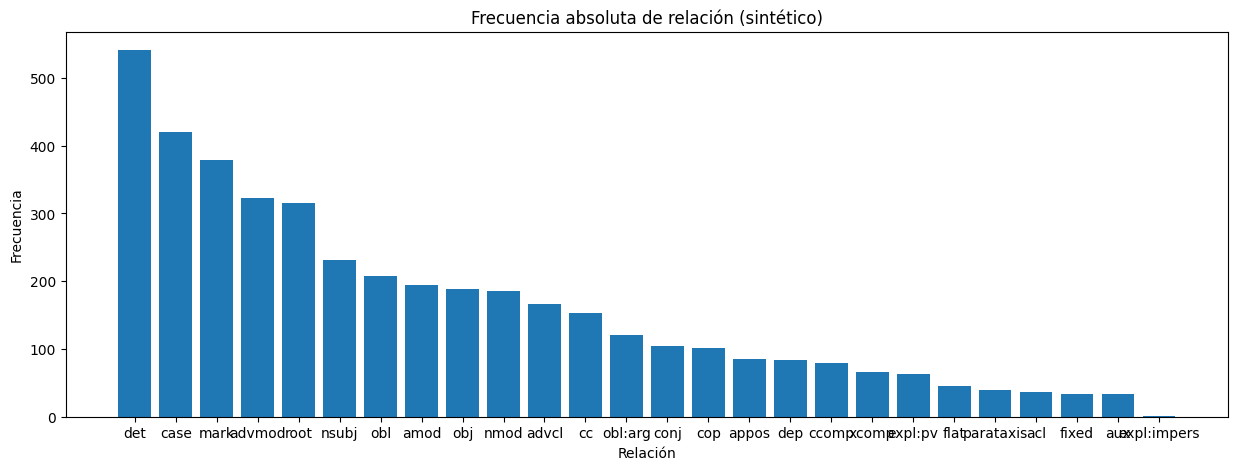

In [ ]:
plt.figure(figsize=(15,5))
plt.bar(df_ud_sin["Relación"], df_ud_sin["Freq_ud_sin"])
plt.title("Frecuencia absoluta de relación (sintético)")
plt.xlabel("Relación")
plt.ylabel("Frecuencia")
plt.show()

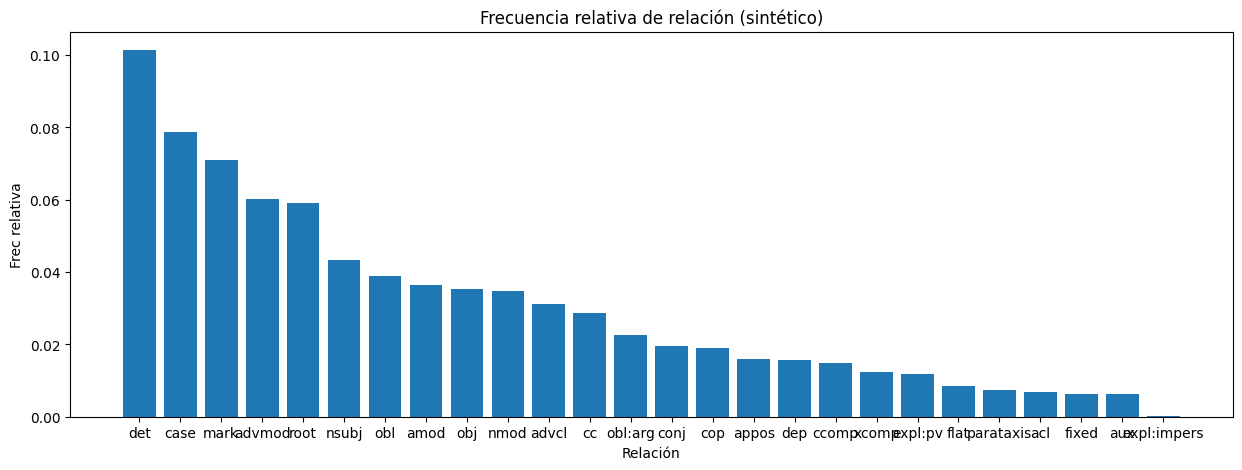

In [ ]:
plt.figure(figsize=(15,5))
plt.bar(df_ud_sin["Relación"], df_ud_sin["Frec relativa"])
plt.title("Frecuencia relativa de relación (sintético)")
plt.xlabel("Relación")
plt.ylabel("Frec relativa")
plt.show()

###Diálogos sintéticos all

In [ ]:
df_ud_all

,Relación,Freq_ud_all,Frec relativa
0,det,"3,605",0.10258
1,case,"2,896",0.08240
2,mark,"2,434",0.06926
3,advmod,"2,029",0.05773
4,root,"1,976",0.05623
5,obj,"1,548",0.04405
6,nsubj,"1,456",0.04143
7,obl,"1,402",0.03989
8,nmod,"1,255",0.03571
9,advcl,"1,244",0.03540


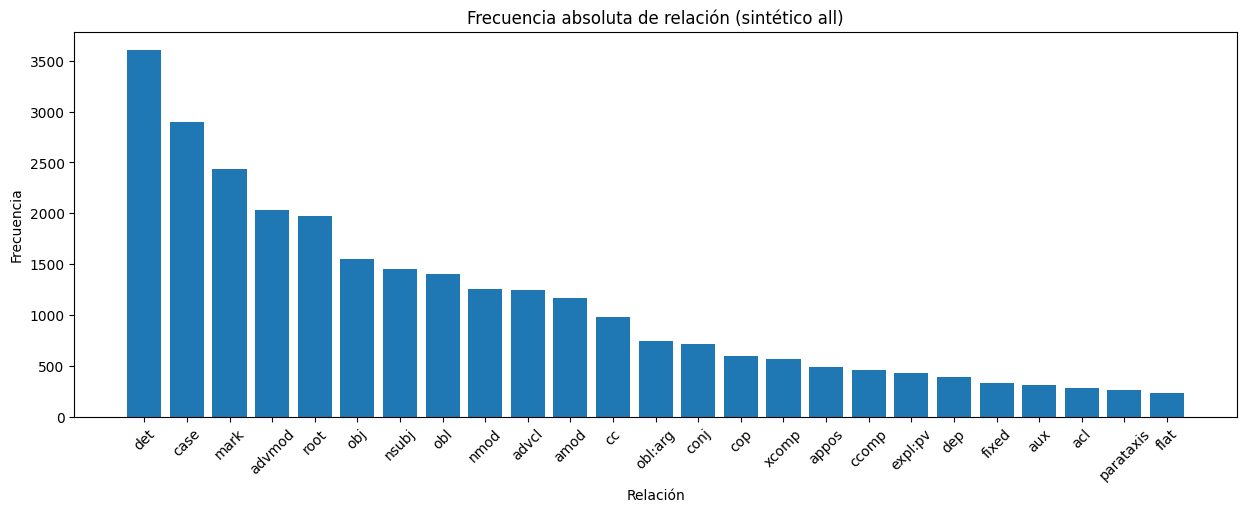

In [ ]:
df_ud_all["Freq_ud_all"] = df_ud_all["Freq_ud_all"].astype(str).str.replace(',', '').astype(float)

plt.figure(figsize=(15,5))
plt.bar(df_ud_all["Relación"], df_ud_all["Freq_ud_all"])

plt.title("Frecuencia absoluta de relación (sintético all)")
plt.xlabel("Relación")
plt.ylabel("Frecuencia")

plt.xticks(rotation=45)
plt.show()

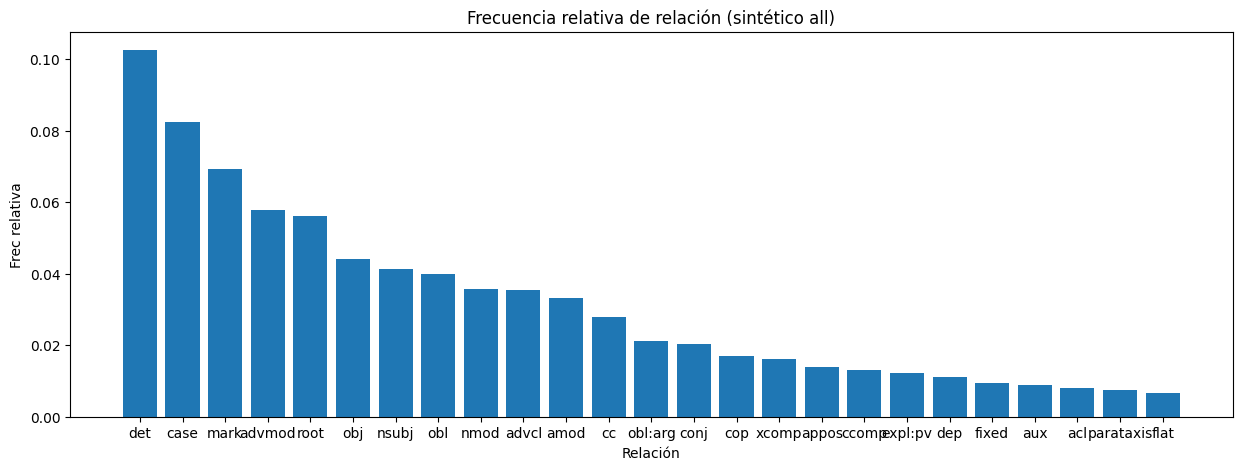

In [ ]:
plt.figure(figsize=(15,5))
plt.bar(df_ud_all["Relación"], df_ud_all["Frec relativa"])
plt.title("Frecuencia relativa de relación (sintético all)")
plt.xlabel("Relación")
plt.ylabel("Frec relativa")
plt.show()

##Comparaciones

###Diálogos espontáneos y diálogos sintéticos

In [ ]:
df_ud_esp = df_ud_esp.rename(columns={"Frecuencia": "Freq_ud_esp"})
df_ud_sin = df_ud_sin.rename(columns={"Frecuencia": "Freq_ud_sin"})

df_ud_compare = pd.merge(
    df_ud_esp,
    df_ud_sin,
    on="Relación",
    how="outer"
).fillna(0)

df_ud_compare["Freq_ud_esp"] = df_ud_compare["Freq_ud_esp"].astype(str).str.replace(',', '').astype(float)
df_ud_compare["Freq_ud_sin"] = df_ud_compare["Freq_ud_sin"].astype(str).str.replace(',', '').astype(float)

df_ud_compare = df_ud_compare.sort_values(by="Freq_ud_esp",ascending=False)
df_ud_compare = df_ud_compare.sort_values(by="Freq_ud_sin",ascending=False)

print(df_ud_compare)

       Relación  Freq_ud_esp  Frec relativa_x  Freq_ud_sin  Frec relativa_y
12          det        247.0          0.05762        541.0          0.10139
6          case        172.0          0.04012        420.0          0.07871
17         mark        166.0          0.03872        379.0          0.07103
2        advmod        268.0          0.06251        322.0          0.06034
24         root        348.0          0.08118        315.0          0.05903
19        nsubj        158.0          0.03686        231.0          0.04329
21          obl         97.0          0.02263        207.0          0.03879
3          amod         74.0          0.01726        194.0          0.03636
20          obj        178.0          0.04152        188.0          0.03523
18         nmod         52.0          0.01213        185.0          0.03467
1         advcl        134.0          0.03126        166.0          0.03111
7            cc         73.0          0.01703        153.0          0.02867
22      obl:

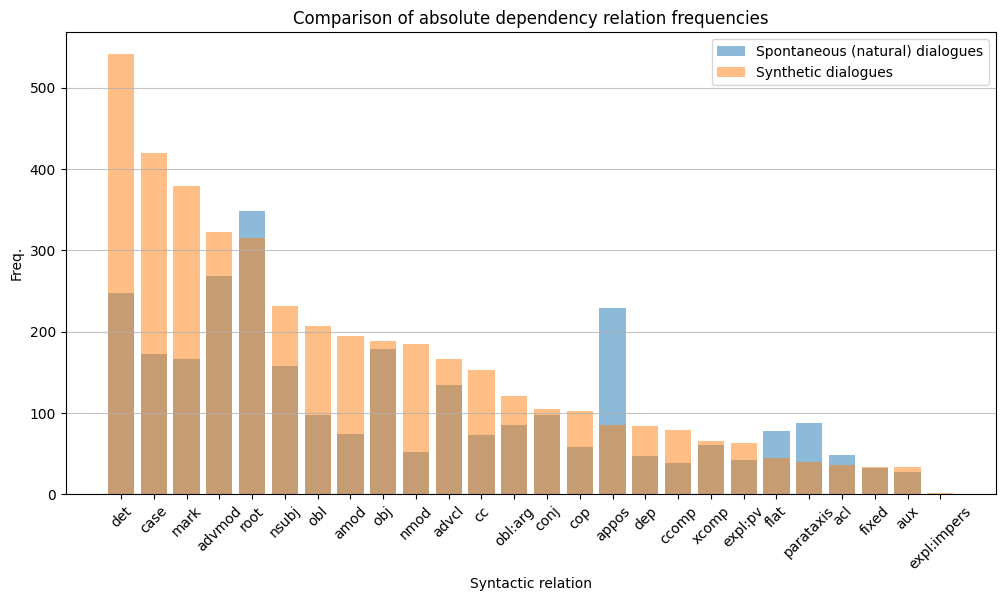

In [ ]:
x = np.arange(len(df_ud_compare["Relación"]))

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_ud_compare["Freq_ud_esp"],
    alpha=0.5,
    label="Spontaneous (natural) dialogues"
)

plt.bar(
    x,
    df_ud_compare["Freq_ud_sin"],
    alpha=0.5,
    label="Synthetic dialogues"
)

plt.xlabel("Syntactic relation")
plt.ylabel("Freq.")
plt.title("Comparison of absolute dependency relation frequencies")
plt.xticks(x, df_ud_compare["Relación"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

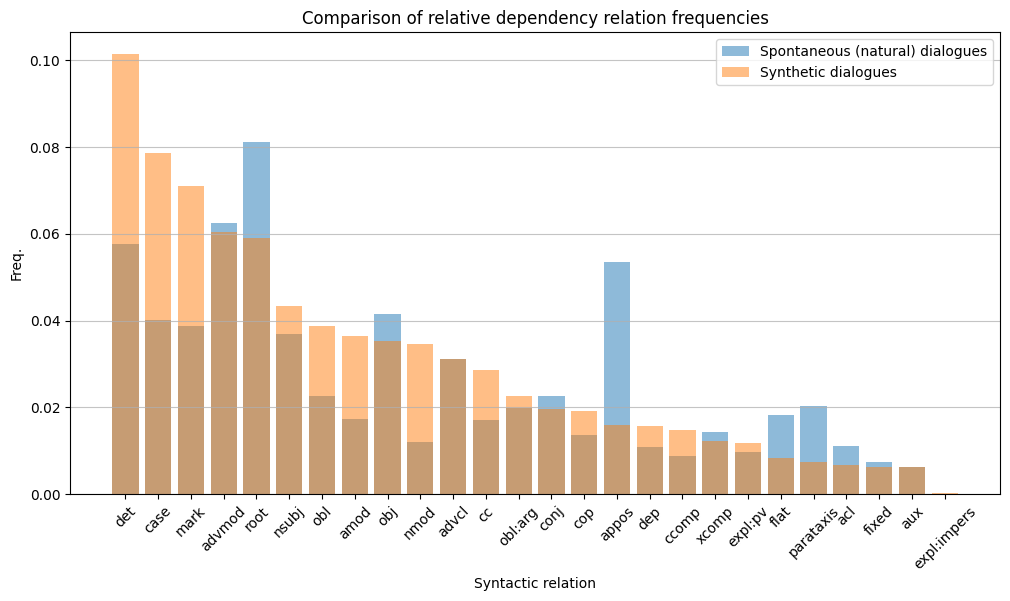

In [ ]:
x = np.arange(len(df_ud_compare["Relación"]))

df_ud_compare["Frec relativa_x"] = df_ud_compare["Frec relativa_x"].astype(str).str.replace('%', '').astype(float)
df_ud_compare["Frec relativa_y"] = df_ud_compare["Frec relativa_y"].astype(str).str.replace('%', '').astype(float)

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_ud_compare["Frec relativa_x"],
    alpha=0.5,
    label="Spontaneous (natural) dialogues"
)

plt.bar(
    x,
    df_ud_compare["Frec relativa_y"],
    alpha=0.5,
    label="Synthetic dialogues"
)

plt.xlabel("Syntactic relation")
plt.ylabel("Freq.")
plt.title("Comparison of relative dependency relation frequencies")
plt.xticks(x, df_ud_compare["Relación"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

###Diálogos espontáneos y diálogos sintéticos all

In [ ]:
df_ud_esp = df_ud_esp.rename(columns={"Frecuencia": "Freq_ud_esp"})
df_ud_all = df_ud_all.rename(columns={"Frecuencia": "Freq_ud_all"})

df_ud_compare = pd.merge(
    df_ud_esp,
    df_ud_all,
    on="Relación",
    how="outer"
).fillna(0)

df_ud_compare["Freq_ud_esp"] = df_ud_compare["Freq_ud_esp"].astype(str).str.replace(',', '').astype(float)
df_ud_compare["Freq_ud_all"] = df_ud_compare["Freq_ud_all"].astype(str).str.replace(',', '').astype(float)

df_ud_compare = df_ud_compare.sort_values(by="Freq_ud_esp",ascending=False)
df_ud_compare = df_ud_compare.sort_values(by="Freq_ud_all",ascending=False)

print(df_ud_compare)

     Relación  Freq_ud_esp  Frec relativa_x  Freq_ud_all  Frec relativa_y
12        det        247.0          0.05762       3605.0          0.10258
6        case        172.0          0.04012       2896.0          0.08240
16       mark        166.0          0.03872       2434.0          0.06926
2      advmod        268.0          0.06251       2029.0          0.05773
23       root        348.0          0.08118       1976.0          0.05623
19        obj        178.0          0.04152       1548.0          0.04405
18      nsubj        158.0          0.03686       1456.0          0.04143
20        obl         97.0          0.02263       1402.0          0.03989
17       nmod         52.0          0.01213       1255.0          0.03571
1       advcl        134.0          0.03126       1244.0          0.03540
3        amod         74.0          0.01726       1166.0          0.03318
7          cc         73.0          0.01703        980.0          0.02789
21    obl:arg         85.0          0.

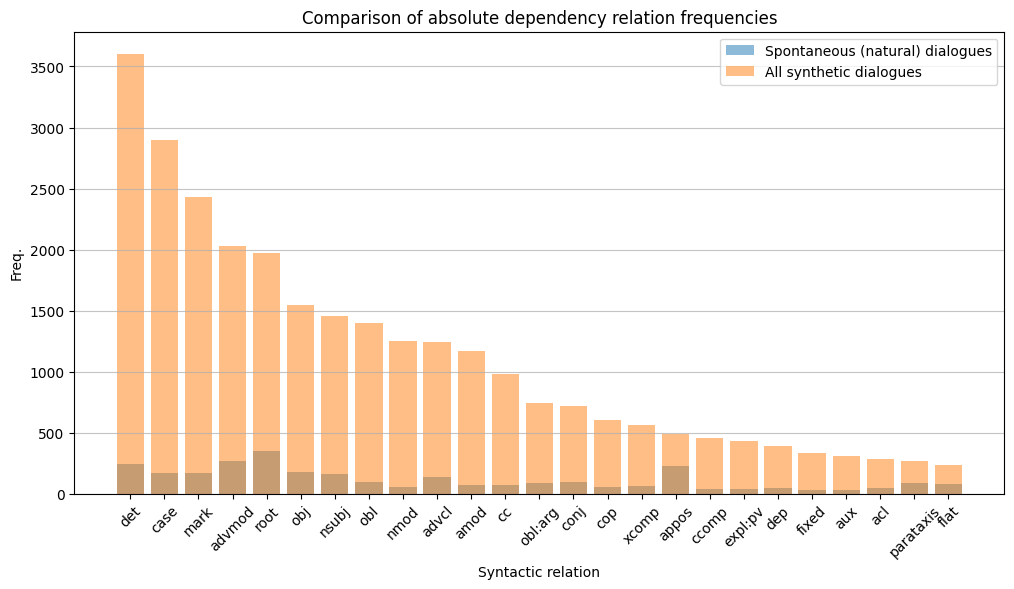

In [ ]:
x = np.arange(len(df_ud_compare["Relación"]))

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_ud_compare["Freq_ud_esp"],
    alpha=0.5,
    label="Spontaneous (natural) dialogues"
)

plt.bar(
    x,
    df_ud_compare["Freq_ud_all"],
    alpha=0.5,
    label="All synthetic dialogues"
)

plt.xlabel("Syntactic relation")
plt.ylabel("Freq.")
plt.title("Comparison of absolute dependency relation frequencies")
plt.xticks(x, df_ud_compare["Relación"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

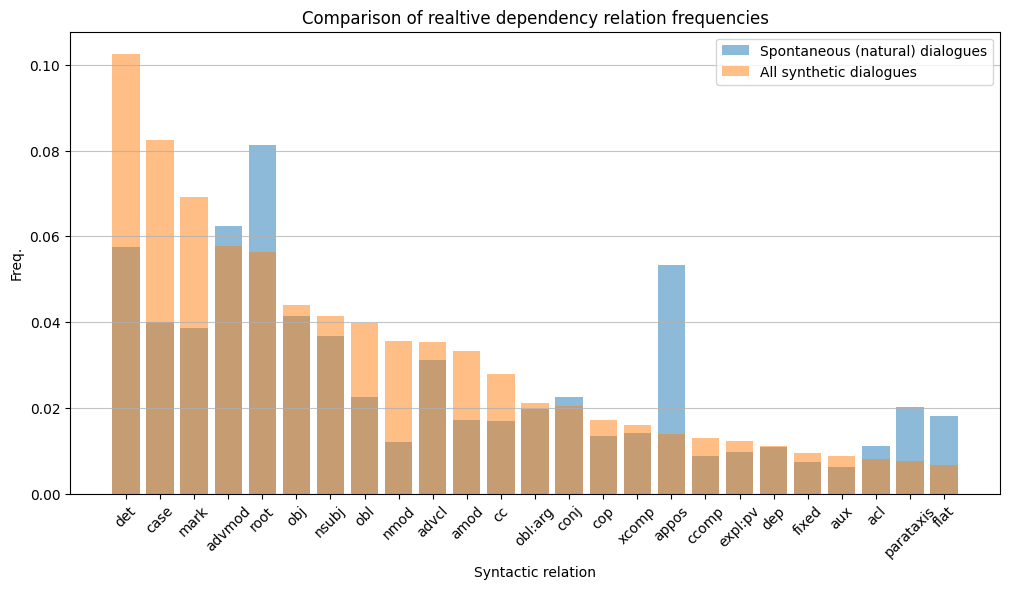

In [ ]:
x = np.arange(len(df_ud_compare["Relación"]))

df_ud_compare["Frec relativa_x"] = df_ud_compare["Frec relativa_x"].astype(str).str.replace('%', '').astype(float)
df_ud_compare["Frec relativa_y"] = df_ud_compare["Frec relativa_y"].astype(str).str.replace('%', '').astype(float)

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_ud_compare["Frec relativa_x"],
    alpha=0.5,
    label="Spontaneous (natural) dialogues"
)

plt.bar(
    x,
    df_ud_compare["Frec relativa_y"],
    alpha=0.5,
    label="All synthetic dialogues"
)

plt.xlabel("Syntactic relation")
plt.ylabel("Freq.")
plt.title("Comparison of realtive dependency relation frequencies")
plt.xticks(x, df_ud_compare["Relación"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

###Diálogos sintéticos y diálogos sintéticos all

In [ ]:
df_ud_sin = df_ud_sin.rename(columns={"Frecuencia": "Freq_ud_sin"})
df_ud_all = df_ud_all.rename(columns={"Frecuencia": "Freq_ud_all"})

df_ud_compare = pd.merge(
    df_ud_sin,
    df_ud_all,
    on="Relación",
    how="outer"
).fillna(0)

df_ud_compare["Freq_ud_sin"] = df_ud_compare["Freq_ud_sin"].astype(str).str.replace(',', '').astype(float)
df_ud_compare["Freq_ud_all"] = df_ud_compare["Freq_ud_all"].astype(str).str.replace(',', '').astype(float)

df_ud_compare = df_ud_compare.sort_values(by="Freq_ud_sin",ascending=False)
df_ud_compare = df_ud_compare.sort_values(by="Freq_ud_all",ascending=False)

print(df_ud_compare)

       Relación  Freq_ud_sin  Frec relativa_x  Freq_ud_all  Frec relativa_y
12          det        541.0          0.10139       3605.0          0.10258
6          case        420.0          0.07871       2896.0          0.08240
17         mark        379.0          0.07103       2434.0          0.06926
2        advmod        322.0          0.06034       2029.0          0.05773
24         root        315.0          0.05903       1976.0          0.05623
20          obj        188.0          0.03523       1548.0          0.04405
19        nsubj        231.0          0.04329       1456.0          0.04143
21          obl        207.0          0.03879       1402.0          0.03989
18         nmod        185.0          0.03467       1255.0          0.03571
1         advcl        166.0          0.03111       1244.0          0.03540
3          amod        194.0          0.03636       1166.0          0.03318
7            cc        153.0          0.02867        980.0          0.02789
22      obl:

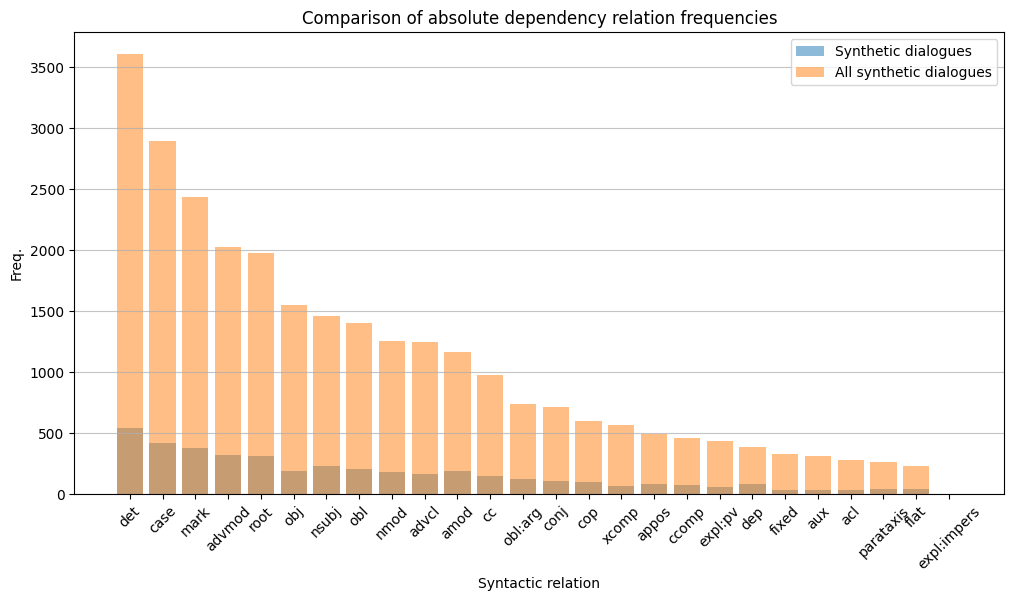

In [ ]:
x = np.arange(len(df_ud_compare["Relación"]))

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_ud_compare["Freq_ud_sin"],
    alpha=0.5,
    label="Synthetic dialogues"
)

plt.bar(
    x,
    df_ud_compare["Freq_ud_all"],
    alpha=0.5,
    label="All synthetic dialogues"
)

plt.xlabel("Syntactic relation")
plt.ylabel("Freq.")
plt.title("Comparison of absolute dependency relation frequencies")
plt.xticks(x, df_ud_compare["Relación"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

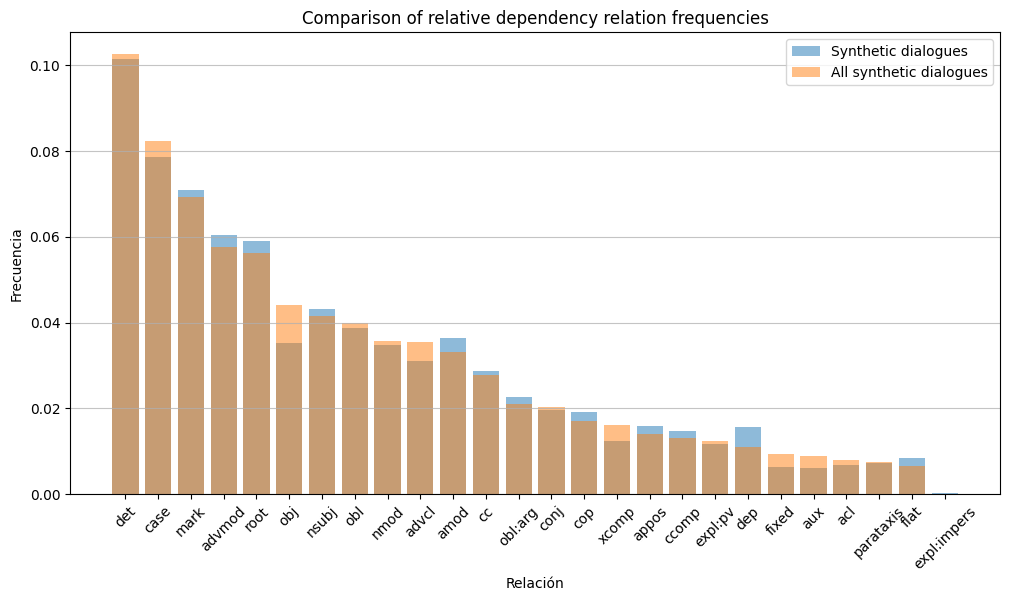

In [ ]:
x = np.arange(len(df_ud_compare["Relación"]))

df_ud_compare["Frec relativa_x"] = df_ud_compare["Frec relativa_x"].astype(str).str.replace('%', '').astype(float)
df_ud_compare["Frec relativa_y"] = df_ud_compare["Frec relativa_y"].astype(str).str.replace('%', '').astype(float)

plt.figure(figsize=(12,6))
plt.bar(
    x,
    df_ud_compare["Frec relativa_x"],
    alpha=0.5,
    label="Synthetic dialogues"
)

plt.bar(
    x,
    df_ud_compare["Frec relativa_y"],
    alpha=0.5,
    label="All synthetic dialogues"
)

plt.xlabel("Relación")
plt.ylabel("Frecuencia")
plt.title("Comparison of relative dependency relation frequencies")
plt.xticks(x, df_ud_compare["Relación"], rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()